# 02 · Modelling: can we predict churn from the first day?

The training code lives in `src/churn/train.py` (run it with `uv run python -m churn.train`). This notebook walks through the result and explains each number.

In [1]:
import json
from IPython.display import Image, display

from churn import train

train.main()
results = json.load(open("../reports/metrics.json"))

{
  "players": 8984,
  "churn_rate": 0.223,
  "train_size": 7187,
  "test_size": 1797,
  "models": {
    "logistic_regression": {
      "cv_roc_auc_mean": 0.694,
      "cv_roc_auc_std": 0.016,
      "roc_auc": 0.683,
      "pr_auc": 0.342,
      "threshold": 0.5,
      "precision": 0.344,
      "recall": 0.67,
      "confusion_matrix": {
        "tn": 885,
        "fp": 512,
        "fn": 132,
        "tp": 268
      },
      "top_20pct": {
        "share_contacted": 0.2,
        "churn_rate_in_top": 0.384,
        "base_churn_rate": 0.223,
        "lift": 1.73,
        "share_of_all_churners_reached": 0.345
      }
    },
    "gradient_boosting": {
      "cv_roc_auc_mean": 0.754,
      "cv_roc_auc_std": 0.011,
      "roc_auc": 0.735,
      "pr_auc": 0.412,
      "threshold": 0.5,
      "precision": 0.384,
      "recall": 0.655,
      "confusion_matrix": {
        "tn": 977,
        "fp": 420,
        "fn": 138,
        "tp": 262
      },
      "top_20pct": {
        "share_contacted":

## Setup

- **80/20 split**, *stratified*: train and test keep the same 22% churn rate.
- **Two models**:
  - *Logistic regression*: a simple, transparent baseline. Behaviour counts go through `log(1 + x)` because they are very skewed.
  - *Gradient boosting* (`HistGradientBoostingClassifier`): many small decision trees, each correcting the last. It can learn curves and interactions.
- `class_weight="balanced"`: churners are only 22% of players, so their mistakes are weighted more. Otherwise a model could score well by predicting "stays" for everyone.

In [2]:
import pandas as pd
rows = {name: {k: v for k, v in m.items() if not isinstance(v, dict)} for name, m in results["models"].items()}
pd.DataFrame(rows)

,logistic_regression,gradient_boosting
cv_roc_auc_mean,0.694,0.754
cv_roc_auc_std,0.016,0.011
roc_auc,0.683,0.735
pr_auc,0.342,0.412
threshold,0.500,0.500
precision,0.344,0.384
recall,0.670,0.655


## How to read these numbers

- **ROC-AUC**: pick one churner and one non-churner at random; the AUC is the chance the model gives the churner the higher risk score. 0.5 is a coin flip, 1.0 is perfect.
- **cv_roc_auc_mean / std**: the same score averaged over 5 different train/validation splits. A small spread means the result is stable, not luck.
- **PR-AUC**: how precise the model stays as it tries to catch more churners. Compare it with the base rate (0.22), which is what random guessing gets.
- **Precision / recall at 0.5**: of the players flagged as churners, how many really churned (precision); of all real churners, how many were flagged (recall).

In [3]:
pd.DataFrame({name: m["top_20pct"] for name, m in results["models"].items()})

,logistic_regression,gradient_boosting
share_contacted,0.200,0.200
churn_rate_in_top,0.384,0.468
base_churn_rate,0.223,0.223
lift,1.730,2.100
share_of_all_churners_reached,0.345,0.420


## The business view: lift

A retention team cannot contact everyone. If it contacts only the **20% of players with the highest risk score**, the table shows how concentrated the churners are in that group compared with picking players at random (`lift`), and what share of all churners it reaches.

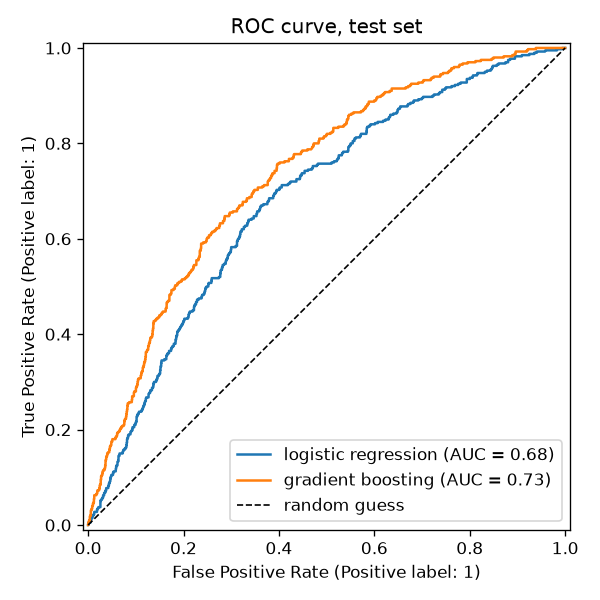

In [4]:
display(Image("../reports/roc_curve.png"))

## What the model relies on

*Permutation importance*: shuffle one column on the test set and measure how much ROC-AUC drops. A big drop means the model really uses that column.

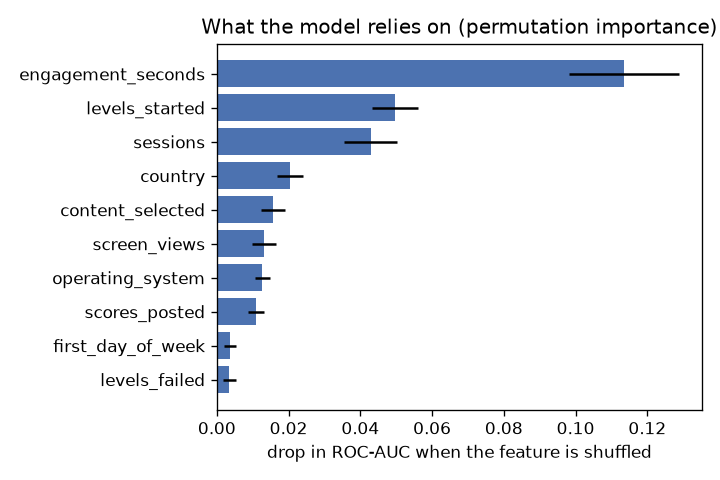

,feature,auc_drop,std
0,engagement_seconds,0.1135,0.0153
1,levels_started,0.0497,0.0065
2,sessions,0.0429,0.0074
3,country,0.0205,0.0036
4,content_selected,0.0157,0.0034
5,screen_views,0.0132,0.0034
6,operating_system,0.0126,0.0021
7,scores_posted,0.0109,0.0023


In [5]:
display(Image("../reports/feature_importance.png"))
pd.DataFrame(results["feature_importance"]).head(8)

Direction of each effect, from the logistic regression (positive = more churn). These are on the log scale, standardised, so compare signs and relative size, not exact values.

In [6]:
pd.Series(results["logistic_coefficients_behaviour"]).to_frame("coefficient")

,coefficient
behaviour__sessions,-0.408
behaviour__scores_posted,-0.336
behaviour__levels_failed,-0.273
behaviour__levels_reset,-0.084
behaviour__content_selected,0.014
behaviour__levels_completed,0.025
behaviour__screen_views,0.150
behaviour__engagement_seconds,0.630
behaviour__levels_started,0.685


## Calibration

Does a predicted 40% risk mean 40% of those players churn? Because of `class_weight="balanced"`, the scores are pushed upwards, so they are good for **ranking** players but should not be read as exact probabilities. If exact probabilities were needed, the next step would be to recalibrate (for example with `CalibratedClassifierCV`).

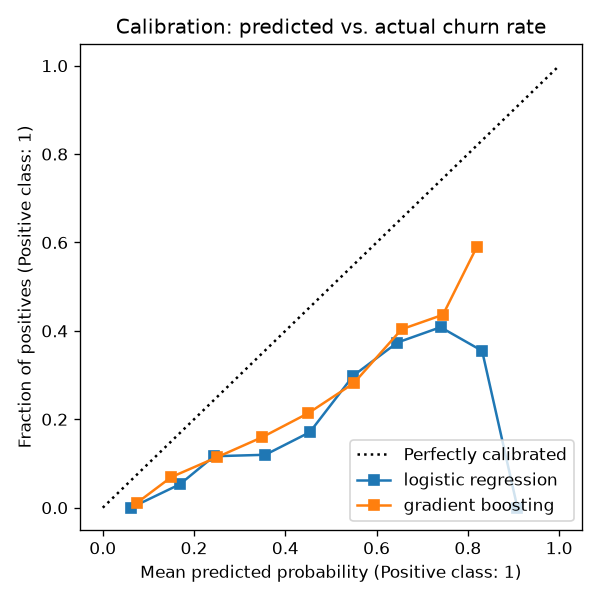

In [7]:
display(Image("../reports/calibration.png"))

## Conclusions

- Gradient boosting beats the linear baseline, as the exploration suggested (the engagement effect is not a straight line).
- The model is a useful **ranking tool**, not a crystal ball: it concentrates churners in the top of the list, which is what a targeted retention campaign needs.
- Main signal: first-day engagement time, levels started and number of sessions. More separate sessions on day one means *less* churn; a single long binge means *more*, up to a point (the heaviest players churn less, see notebook 01).
- Next steps: features about *how* the day went (time between sessions, difficulty reached), recalibrated probabilities, and a real experiment (notebook 03) to check whether contacting high-risk players actually reduces churn.